<a href="https://colab.research.google.com/github/TD4C/ct-to-synthetic-xray/blob/main/notebooks/CT_to_Synthetic_Xray_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CT to Synthetic DRR — Mô hình học sâu tạo ảnh chiếu tổng hợp từ CT 3D

## 1. Giới thiệu

Dự án minh họa quy trình sử dụng học sâu để dự đoán các ảnh chiếu 2D từ dữ liệu chụp cắt lớp vi tính (CT) 3D. Mô hình nhận một thể tích CT làm đầu vào và tạo ra hai ảnh chiếu tổng hợp theo hai hướng: AP (trước–sau) và Lateral (bên).

Notebook được triển khai bằng Python, PyTorch và Google Colab, hỗ trợ tiền xử lý dữ liệu CT, tạo ảnh tham chiếu, huấn luyện mô hình, đánh giá kết quả và xem các vùng hoặc lát cắt của thể tích CT.

## 2. Nguyên lý hoạt động

Dữ liệu CT được chuẩn hóa và đưa về kích thước đầu vào cố định. Từ thể tích CT, chương trình tạo các ảnh tham chiếu dạng DRR bằng phép chiếu trung bình cường độ theo các trục không gian.

Mạng nơ-ron 3D sau đó được huấn luyện để dự đoán hai ảnh tham chiếu này. Quá trình huấn luyện sử dụng hàm mất mát L1, theo dõi sai số trên tập huấn luyện và tập kiểm định, đồng thời lưu lại mô hình có Validation L1 tốt nhất.

**Lưu ý quan trọng:** các ảnh tham chiếu trong dự án được tạo bằng phép chiếu số học từ CT, không phải ảnh X-quang thật và không phải mô phỏng vật lý đầy đủ của quá trình chụp X-quang.

## 3. Dữ liệu và phạm vi hỗ trợ

- Đầu vào: thể tích CT 3D ở định dạng NIfTI (`.nii` hoặc `.nii.gz`).
- Kích thước đầu vào sau tiền xử lý: `48 × 48 × 64`.
- Đầu ra: hai ảnh chiếu tổng hợp AP và Lateral.
- Bộ dữ liệu tham khảo: [TotalSegmentator — Zenodo](https://zenodo.org/records/8367170).
- Cấu hình mặc định sử dụng tối đa 40 ca CT để giới hạn thời gian chạy trên Google Colab.

Notebook hiện tại chỉ xử lý CT. Không thể mặc định áp dụng cùng quy trình cho MRI vì dữ liệu MRI có đặc tính cường độ và yêu cầu tiền xử lý khác.

## 4. Quy trình thực hiện

1. Cài đặt thư viện và kiểm tra thiết bị tính toán.
2. Tải và tìm các thể tích CT hợp lệ.
3. Chuẩn hóa CT và tạo ảnh tham chiếu dạng DRR.
4. Chia dữ liệu thành các tập huấn luyện, kiểm định và kiểm tra.
5. Xây dựng mạng nơ-ron 3D và huấn luyện mô hình.
6. Theo dõi đường cong loss và đánh giá bằng MAE, PSNR.
7. Trực quan hóa CT, ảnh tham chiếu và ảnh do mô hình dự đoán.
8. Lưu trọng số mô hình và các chỉ số đánh giá.

## 5. Giới hạn sử dụng

Đây là dự án thử nghiệm phục vụ học tập và nghiên cứu xử lý ảnh y tế. Kết quả chỉ phản ánh khả năng mô hình xấp xỉ các ảnh tham chiếu tổng hợp được tạo theo quy trình của notebook.

Mô hình chưa được xác nhận trên ảnh X-quang lâm sàng và không được sử dụng để chẩn đoán, điều trị hoặc thay thế quyết định của chuyên gia y tế.

## 6. Hướng dẫn chạy

1. Mở notebook bằng Google Colab.
2. Chọn GPU nếu môi trường được cung cấp GPU.
3. Chạy lần lượt các ô mã từ trên xuống dưới.
4. Chờ hoàn tất tiền xử lý và huấn luyện.
5. Xem các chỉ số đánh giá, hình ảnh dự đoán và tải mô hình nếu cần.

Nếu phiên Colab bị đặt lại, dữ liệu và kết quả lưu trong bộ nhớ tạm của phiên có thể bị mất. Khi đó, cần tải lại dữ liệu hoặc khôi phục các tệp đã lưu trước đó.

## Bước 1 — Thiết lập môi trường và kiểm tra GPU

Cài đặt các thư viện cần thiết, khởi tạo bộ sinh số ngẫu nhiên và xác định thiết bị thực thi.

Nếu có GPU tương thích, chương trình sẽ ưu tiên sử dụng GPU để tăng tốc huấn luyện. Nếu chỉ có CPU, quá trình xử lý thể tích CT 3D có thể chậm hơn đáng kể.

In [1]:
import sys, subprocess, os, random, math, json, time, hashlib, zipfile
from pathlib import Path

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "nibabel", "matplotlib", "tqdm", "ipywidgets", "requests"
])

import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CẢNH BÁO: hiện đang dùng CPU; huấn luyện 3D sẽ chậm. Hãy bật GPU trong Runtime nếu có thể.")

Thiết bị: cuda
GPU: Tesla T4


## Bước 2 — Khởi tạo đường dẫn dữ liệu và kết quả

Thư mục gốc của dự án trong Google Colab là `/content/ct_to_synthetic_xray`.

Dữ liệu gốc, bộ nhớ đệm tiền xử lý và kết quả huấn luyện được lưu trong các thư mục riêng để dễ quản lý.

Các đường dẫn này phục vụ môi trường Colab, không phải đường dẫn cố định trên máy tính cá nhân. Bộ nhớ của phiên Colab có tính tạm thời, do đó nên tải về hoặc sao lưu các kết quả cần giữ lại.

In [2]:
ROOT_DIR = Path("/content/ct_to_synthetic_xray")
DATA_DIR = ROOT_DIR / "data"
DATASET_DIR = DATA_DIR / "totalsegmentator_small"
ZIP_PATH = DATA_DIR / "Totalsegmentator_dataset_small_v2.zip"
PART_PATH = DATA_DIR / "Totalsegmentator_dataset_small_v2.zip.part"
CACHE_DIR = DATA_DIR / "prepared_cache"
OUTPUT_DIR = ROOT_DIR / "outputs" / "trained_model"

for folder in (DATA_DIR, DATASET_DIR, CACHE_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DOWNLOAD_URL = (
    "https://zenodo.org/records/8367170/files/"
    "Totalsegmentator_dataset_small_v2.zip?download=1"
)

print("Thư mục gốc:", ROOT_DIR)
print("Bộ dữ liệu:", DATASET_DIR)
print("Thư mục lưu mô hình:", OUTPUT_DIR)

Thư mục gốc: /content/ct_to_synthetic_xray
Bộ dữ liệu: /content/ct_to_synthetic_xray/data/totalsegmentator_small
Thư mục lưu mô hình: /content/ct_to_synthetic_xray/outputs/trained_model


## Bước 3 — Tải và chuẩn bị dữ liệu CT

Chương trình tìm các thể tích CT đã có trước khi tải dữ liệu để tránh tải lại khi không cần thiết.

Gói dữ liệu nén hiện có dung lượng khoảng 3,0 GiB. Quá trình tải có hỗ trợ tiếp tục từ tệp tạm nếu máy chủ cho phép. Sau khi tải hoàn tất, chương trình kiểm tra tính hợp lệ của tệp ZIP và chỉ giải nén các tệp CT phù hợp.

**Lưu ý:** bộ dữ liệu lớn không được đưa vào repository GitHub. Khi chạy trên một phiên Colab mới, có thể cần tải dữ liệu lại.

In [4]:
from pathlib import Path
import zipfile
import requests
import nibabel as nib
from tqdm.auto import tqdm

# ==================================================
# CẤU HÌNH
# ==================================================

ROOT_DIR = Path("/content/ct_to_synthetic_xray")
DATA_DIR = ROOT_DIR / "data"
DATASET_DIR = DATA_DIR / "totalsegmentator_small"

ZIP_PATH = DATA_DIR / "Totalsegmentator_dataset_small_v2.zip"
PART_PATH = DATA_DIR / "Totalsegmentator_dataset_small_v2.zip.part"

DATA_DIR.mkdir(parents=True, exist_ok=True)
DATASET_DIR.mkdir(parents=True, exist_ok=True)

# Bản sao Dropbox được liên kết từ trang Zenodo
DOWNLOAD_URL = (
    "https://www.dropbox.com/scl/fi/"
    "1fl4t3sc94tjmf6nq02ar/"
    "Totalsegmentator_dataset_small_v2.zip"
    "?rlkey=b1mk4iple8wc05mdk64wp183v&dl=1"
)


# ==================================================
# 1. TÌM CÁC FILE CT ĐÃ CÓ
# ==================================================

def find_ct_files():
    if not DATASET_DIR.exists():
        return []

    # Tìm đúng tên file CT trước, tránh quét mọi loại NIfTI
    paths = sorted(DATASET_DIR.rglob("ct.nii.gz"))

    if not paths:
        paths = sorted(DATASET_DIR.rglob("ct.nii"))

    valid = []

    for p in paths:
        try:
            img = nib.load(str(p))

            if len(img.shape) == 3:
                valid.append(p)

        except Exception:
            continue

    return valid


# ==================================================
# 2. TẢI FILE ZIP, CÓ THỂ TẢI TIẾP
# ==================================================

def download_dataset_resumable():
    # Nếu file tạm đã tải xong nhưng chưa đổi tên
    if PART_PATH.exists() and zipfile.is_zipfile(PART_PATH):
        if ZIP_PATH.exists():
            ZIP_PATH.unlink()

        PART_PATH.replace(ZIP_PATH)
        print("Đã khôi phục file ZIP tải hoàn chỉnh.")
        return

    existing = PART_PATH.stat().st_size if PART_PATH.exists() else 0

    headers = {"User-Agent": "Mozilla/5.0"}

    print("Nguồn tải: Dropbox")
    print(f"Dữ liệu đã tải trước đó: {existing / 1024**3:.2f} GiB")
    print("Đang tải dataset...")

    with requests.Session() as session:
        if existing > 0:
            # Yêu cầu máy chủ gửi tiếp từ vị trí đã tải
            headers["Range"] = f"bytes={existing}-"

        response = session.get(
            DOWNLOAD_URL,
            headers=headers,
            stream=True,
            timeout=(30, 180),
        )

        # Nếu máy chủ không hỗ trợ tiếp tục tải
        if existing > 0 and response.status_code == 200:
            existing = 0
            mode = "wb"

        elif existing > 0 and response.status_code == 206:
            mode = "ab"

        elif response.status_code == 416 and existing > 0:
            response.close()
            PART_PATH.unlink(missing_ok=True)
            print("File tạm không thể tải tiếp, bắt đầu tải lại.")
            return download_dataset_resumable()

        else:
            mode = "wb"
            existing = 0

        try:
            response.raise_for_status()

            content_range = response.headers.get("Content-Range", "")
            if "/" in content_range:
                size_text = content_range.rsplit("/", 1)[1]
                total = int(size_text) if size_text.isdigit() else None
            else:
                length = int(response.headers.get("Content-Length", 0))
                total = existing + length if length > 0 else None

            with open(PART_PATH, mode) as f, tqdm(
                total=total,
                initial=existing,
                unit="B",
                unit_scale=True,
                unit_divisor=1024,
                desc="Tải dataset",
            ) as bar:
                for chunk in response.iter_content(
                    chunk_size=4 * 1024 * 1024
                ):
                    if chunk:
                        f.write(chunk)
                        bar.update(len(chunk))

        finally:
            response.close()

    # Kiểm tra ZIP có hoàn chỉnh hay không
    if not zipfile.is_zipfile(PART_PATH):
        raise RuntimeError(
            "File ZIP chưa hoàn chỉnh hoặc không hợp lệ. "
            "Hãy chạy lại cell để tiếp tục tải."
        )

    if ZIP_PATH.exists():
        ZIP_PATH.unlink()

    PART_PATH.replace(ZIP_PATH)

    print(
        f"Tải hoàn tất: {ZIP_PATH.stat().st_size / 1024**3:.2f} GiB"
    )


# ==================================================
# 3. CHỈ GIẢI NÉN ẢNH CT, BỎ QUA MASK PHÂN ĐOẠN
# ==================================================

def extract_ct_only():
    print("Đang đọc danh sách file trong ZIP...")

    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        ct_members = [
            info for info in archive.infolist()
            if not info.is_dir()
            and Path(info.filename).name.lower() in {
                "ct.nii.gz",
                "ct.nii",
            }
        ]

        if not ct_members:
            raise FileNotFoundError(
                "Không thấy ct.nii.gz hoặc ct.nii trong ZIP. "
                "Cần kiểm tra cấu trúc bên trong dataset."
            )

        print(f"Tìm thấy {len(ct_members)} file CT trong ZIP.")

        for info in tqdm(
            ct_members,
            desc="Giải nén ảnh CT",
            unit="file",
        ):
            target = DATASET_DIR / info.filename

            # Không giải nén lại nếu file đã có đầy đủ
            if target.exists() and target.stat().st_size == info.file_size:
                continue

            target.parent.mkdir(parents=True, exist_ok=True)
            archive.extract(info, path=DATASET_DIR)


# ==================================================
# 4. THỰC HIỆN
# ==================================================

ct_candidates = find_ct_files()

if not ct_candidates:
    # Xóa file ZIP lỗi để tránh dùng nhầm
    if ZIP_PATH.exists() and not zipfile.is_zipfile(ZIP_PATH):
        ZIP_PATH.unlink()

    if not ZIP_PATH.exists():
        download_dataset_resumable()

    extract_ct_only()
    ct_candidates = find_ct_files()

if not ct_candidates:
    raise FileNotFoundError(
        "Không tìm thấy ảnh CT 3D hợp lệ sau khi tải và giải nén."
    )

print(f"\nTìm thấy {len(ct_candidates)} file CT 3D hợp lệ:")

for p in ct_candidates[:8]:
    print("-", p.relative_to(DATASET_DIR))

if len(ct_candidates) > 8:
    print(f"... và {len(ct_candidates) - 8} ca khác")

Nguồn tải: Dropbox
Dữ liệu đã tải trước đó: 0.54 GiB
Đang tải dataset...


Tải dataset:  18%|#7        | 552M/3.04G [00:00<?, ?B/s]

Tải hoàn tất: 3.04 GiB
Đang đọc danh sách file trong ZIP...
Tìm thấy 102 file CT trong ZIP.


Giải nén ảnh CT:   0%|          | 0/102 [00:00<?, ?file/s]


Tìm thấy 102 file CT 3D hợp lệ:
- s0011/ct.nii.gz
- s0058/ct.nii.gz
- s0223/ct.nii.gz
- s0250/ct.nii.gz
- s0310/ct.nii.gz
- s0344/ct.nii.gz
- s0357/ct.nii.gz
- s0358/ct.nii.gz
... và 94 ca khác


## Bước 4 — Tiền xử lý CT và tạo ảnh tham chiếu

Các thể tích CT được đưa về cùng quy ước hướng không gian và chuẩn hóa cường độ. Để giảm bộ nhớ sử dụng, dữ liệu được lấy mẫu và nội suy về kích thước `48 × 48 × 64`.

Từ thể tích đã chuẩn hóa, chương trình tạo hai ảnh tham chiếu:

- **AP:** phép chiếu trung bình theo trục trước–sau.
- **Lateral:** phép chiếu trung bình theo trục trái–phải.

Các ảnh này là ảnh chiếu tổng hợp được sử dụng làm mục tiêu huấn luyện. Chúng không phải ảnh X-quang thật và không mô phỏng đầy đủ các yếu tố vật lý của thiết bị chụp.

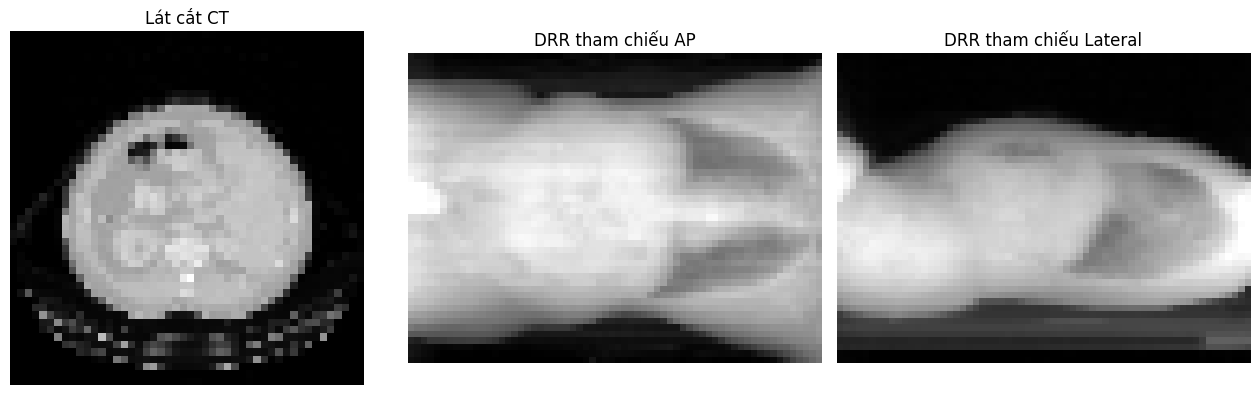

Kích thước CT gốc: (311, 311, 431)
Kích thước đưa vào mô hình: (48, 48, 64)


In [5]:
from nibabel.orientations import io_orientation, axcodes2ornt, ornt_transform, apply_orientation

# Thứ tự trục sau chuẩn hóa: trái-phải, trước-sau, dưới-trên (RAS).
TARGET_SHAPE = (48, 48, 64)  # X, Y, Z


def normalize_projection(image):
    image = np.asarray(image, dtype=np.float32)
    lo, hi = np.percentile(image, (1.0, 99.5))
    if not np.isfinite(lo) or not np.isfinite(hi) or hi <= lo + 1e-6:
        return np.zeros_like(image, dtype=np.float32)
    image = np.clip((image - lo) / (hi - lo), 0.0, 1.0)
    return np.power(image, 0.75).astype(np.float32)


def make_reference_drr(volume_norm):
    """Tạo hai ảnh chiếu tham chiếu 2D từ thể tích chuẩn hóa X,Y,Z."""
    # Trung bình theo chiều trước-sau tạo hình chiếu AP; theo trái-phải tạo hình chiếu bên.
    ap = volume_norm.mean(axis=1)       # X,Z => 48 x 64
    lateral = volume_norm.mean(axis=0)  # Y,Z => 48 x 64
    return np.stack([normalize_projection(ap), normalize_projection(lateral)], axis=0)


def preprocess_ct(path):
    """Đọc CT 3D, giảm mẫu trước khi đổi hướng để hạn chế dùng RAM, rồi chuẩn hóa."""
    img = nib.load(str(path))
    if len(img.shape) != 3:
        raise ValueError(f"Chỉ hỗ trợ thể tích CT 3D; file {path} có shape {img.shape}")

    raw_shape = tuple(int(v) for v in img.shape)
    # Lấy mẫu trực tiếp từ ArrayProxy để không cần nạp cả thể tích độ phân giải cao vào RAM.
    steps = tuple(max(1, int(math.ceil(dim / 64))) for dim in raw_shape)
    sampled = np.asarray(img.dataobj[::steps[0], ::steps[1], ::steps[2]], dtype=np.float32)
    source_ornt = io_orientation(img.affine)
    target_ornt = axcodes2ornt(("R", "A", "S"))
    transform = ornt_transform(source_ornt, target_ornt)
    sampled = apply_orientation(sampled, transform)
    sampled = np.nan_to_num(sampled, nan=-1000.0, posinf=1500.0, neginf=-1000.0)

    tensor = torch.from_numpy(np.ascontiguousarray(sampled)).float()[None, None]
    tensor = F.interpolate(tensor, size=TARGET_SHAPE, mode="trilinear", align_corners=False)
    hu = tensor[0, 0].cpu().numpy()
    # Cửa sổ đơn giản cho CT: -1000 HU -> 0, 1500 HU -> 1.
    volume_norm = np.clip((np.clip(hu, -1000.0, 1500.0) + 1000.0) / 2500.0, 0.0, 1.0)
    return volume_norm.astype(np.float32), raw_shape


def cache_key(path):
    token = hashlib.sha1(str(Path(path).resolve()).encode("utf-8")).hexdigest()[:16]
    return CACHE_DIR / f"ct_{token}.npz"


def prepare_case(path, force=False):
    cache_path = cache_key(path)
    if cache_path.exists() and not force:
        data = np.load(cache_path)
        return {
            "path": str(path),
            "volume": data["volume"].astype(np.float32),
            "target": data["target"].astype(np.float32),
            "raw_shape": tuple(int(v) for v in data["raw_shape"]),
        }
    volume, raw_shape = preprocess_ct(path)
    target = make_reference_drr(volume)
    np.savez_compressed(
        cache_path, volume=volume, target=target, raw_shape=np.asarray(raw_shape, dtype=np.int32)
    )
    return {"path": str(path), "volume": volume, "target": target, "raw_shape": raw_shape}


# Xem thử một ca trước khi tạo tập huấn luyện.
preview_case = prepare_case(ct_candidates[0])
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(preview_case["volume"][:, :, TARGET_SHAPE[2] // 2].T, cmap="gray", origin="lower")
ax[0].set_title("Lát cắt CT")
ax[1].imshow(preview_case["target"][0], cmap="gray", origin="lower")
ax[1].set_title("DRR tham chiếu AP")
ax[2].imshow(preview_case["target"][1], cmap="gray", origin="lower")
ax[2].set_title("DRR tham chiếu Lateral")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print("Kích thước CT gốc:", preview_case["raw_shape"])
print("Kích thước đưa vào mô hình:", preview_case["volume"].shape)

## Bước 5 — Chuẩn bị và chia tập dữ liệu

Mỗi thể tích CT được tiền xử lý thành một mẫu dữ liệu. Các mẫu được xáo trộn theo seed cố định trước khi chia thành ba tập:

- Tập huấn luyện (Train): dùng để cập nhật trọng số mô hình.
- Tập kiểm định (Validation): theo dõi sai số trong quá trình huấn luyện và lựa chọn checkpoint.
- Tập kiểm tra (Test): đánh giá mô hình sau huấn luyện.

Tỷ lệ chia dự kiến là 70% / 15% / 15%, với điều chỉnh nhỏ khi số lượng mẫu ít. Cấu hình mặc định giới hạn ở tối đa 40 ca CT; có thể tăng giới hạn khi tài nguyên tính toán cho phép.

Các chỉ số có thể thay đổi theo tập dữ liệu được chọn và điều kiện thực thi. Kết quả của một bộ dữ liệu nhỏ không đủ để kết luận mô hình có thể tổng quát hóa tốt trên dữ liệu lâm sàng.

In [6]:
MAX_CASES = 40   # Có thể tăng lên 60 hoặc None để dùng tất cả ca
BATCH_SIZE = 1   # Giữ nhỏ để phù hợp GPU Colab

usable_paths = list(ct_candidates)
random.Random(SEED).shuffle(usable_paths)
if MAX_CASES is not None:
    usable_paths = usable_paths[:min(int(MAX_CASES), len(usable_paths))]
if len(usable_paths) < 6:
    raise RuntimeError("Cần ít nhất 6 thể tích CT để chia tập huấn luyện/kiểm định/kiểm tra.")

prepared_cases = []
for p in tqdm(usable_paths, desc="Chuẩn bị ca CT"):
    try:
        prepared_cases.append(prepare_case(p))
    except Exception as exc:
        print(f"Bỏ qua file lỗi {p.name}: {exc}")

if len(prepared_cases) < 6:
    raise RuntimeError("Sau tiền xử lý còn ít hơn 6 ca hợp lệ. Kiểm tra dữ liệu đầu vào.")

# Trộn ở mức ca rồi chia 70% train, 15% validation, 15% test.
rng = np.random.default_rng(SEED)
order = rng.permutation(len(prepared_cases)).tolist()
n_test = max(1, round(len(order) * 0.15))
n_val = max(1, round(len(order) * 0.15))
if n_test + n_val >= len(order):
    n_test, n_val = 1, 1

test_ids = order[:n_test]
val_ids = order[n_test:n_test + n_val]
train_ids = order[n_test + n_val:]
train_cases = [prepared_cases[i] for i in train_ids]
val_cases = [prepared_cases[i] for i in val_ids]
test_cases = [prepared_cases[i] for i in test_ids]

class DRRDataset(Dataset):
    def __init__(self, cases):
        self.cases = cases
    def __len__(self):
        return len(self.cases)
    def __getitem__(self, index):
        case = self.cases[index]
        x = torch.from_numpy(case["volume"][None]).float()   # [1, X, Y, Z]
        y = torch.from_numpy(case["target"]).float()         # [2, X, Z]
        return x, y

train_loader = DataLoader(DRRDataset(train_cases), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(DRRDataset(val_cases), batch_size=1, shuffle=False, num_workers=0)
test_loader = DataLoader(DRRDataset(test_cases), batch_size=1, shuffle=False, num_workers=0)

print(f"Tổng số ca đã chuẩn bị: {len(prepared_cases)}")
print(f"Train: {len(train_cases)} | Validation: {len(val_cases)} | Test: {len(test_cases)}")
print("Một số ca train:")
for case in train_cases[:5]:
    print("-", Path(case["path"]).name)

Chuẩn bị ca CT:   0%|          | 0/40 [00:00<?, ?it/s]

Tổng số ca đã chuẩn bị: 40
Train: 28 | Validation: 6 | Test: 6
Một số ca train:
- ct.nii.gz
- ct.nii.gz
- ct.nii.gz
- ct.nii.gz
- ct.nii.gz


## Bước 6 — Xây dựng mạng nơ-ron 3D

Mô hình `CTToSyntheticXrayNet` sử dụng các lớp tích chập 3D để trích xuất đặc trưng từ thể tích CT.

Đặc trưng không gian được tổng hợp theo hai hướng, sau đó đưa qua hai nhánh dự đoán 2D riêng biệt để tạo ảnh AP và Lateral.

Đầu vào là thể tích CT có một kênh với kích thước `48 × 48 × 64`. Đầu ra gồm hai ảnh chiếu có kích thước `48 × 64`.

Đây là kiến trúc thử nghiệm gọn nhẹ để chạy trên môi trường Google Colab, không phải một mô hình đã được xác nhận cho ứng dụng chẩn đoán hình ảnh.

In [24]:
class CTToSyntheticXrayNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv3d(1, 8, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm3d(8, affine=True),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv3d(8, 8, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm3d(8, affine=True),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv3d(8, 12, kernel_size=3, padding=1, bias=False),
            nn.InstanceNorm3d(12, affine=True),
            nn.LeakyReLU(0.1, inplace=True),
        )
        self.ap_head = nn.Sequential(
            nn.Conv2d(12, 8, kernel_size=3, padding=1),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv2d(8, 1, kernel_size=1),
            nn.Sigmoid(),
        )
        self.lateral_head = nn.Sequential(
            nn.Conv2d(12, 8, kernel_size=3, padding=1),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Conv2d(8, 1, kernel_size=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        # x: [B, 1, X, Y, Z]
        features = self.encoder(x)
        ap_features = features.mean(dim=3)       # Chiếu qua trục Y -> [B,C,X,Z]
        lateral_features = features.mean(dim=2)  # Chiếu qua trục X -> [B,C,Y,Z]
        ap = self.ap_head(ap_features)[:, 0]
        lateral = self.lateral_head(lateral_features)[:, 0]
        return torch.stack([ap, lateral], dim=1)  # [B,2,48,64]


model = CTToSyntheticXrayNet().to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
loss_function = nn.L1Loss()
print(model)
print("Số tham số có thể học:", sum(p.numel() for p in model.parameters() if p.requires_grad))

CTToSyntheticXrayNet(
  (encoder): Sequential(
    (0): Conv3d(1, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
    (1): InstanceNorm3d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
    (2): LeakyReLU(negative_slope=0.1, inplace=True)
    (3): Conv3d(8, 8, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
    (4): InstanceNorm3d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
    (5): LeakyReLU(negative_slope=0.1, inplace=True)
    (6): Conv3d(8, 12, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
    (7): InstanceNorm3d(12, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
    (8): LeakyReLU(negative_slope=0.1, inplace=True)
  )
  (ap_head): Sequential(
    (0): Conv2d(12, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.1, inplace=True)
    (2): Conv2d(8, 1, kernel_size=(1, 1), stride=(1, 1))
    (3): Sigmoid()
  

## Bước 7 — Huấn luyện và lưu checkpoint

Mô hình được huấn luyện bằng hàm mất mát L1 và bộ tối ưu AdamW. Sau mỗi epoch, chương trình tính sai số trên tập huấn luyện và tập kiểm định.

Checkpoint có Validation L1 thấp nhất được lưu thành `best_model.pt`. Lịch sử Train L1 và Validation L1 được lưu trong `training_history.json`.

Cấu hình mặc định là 30 epoch với batch size bằng 1 để hạn chế mức sử dụng bộ nhớ GPU. Số epoch cao hơn không bảo đảm chất lượng mô hình tốt hơn; cần đánh giá đường cong loss và hình ảnh dự đoán trước khi điều chỉnh cấu hình.

In [25]:
EPOCHS = 30  # Tăng lên 20-30 nếu muốn huấn luyện lâu hơn và GPU còn đủ thời gian
BEST_MODEL_PATH = OUTPUT_DIR / "best_model.pt"
HISTORY_PATH = OUTPUT_DIR / "training_history.json"

history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()
    model.train()
    train_sum, train_count = 0.0, 0
    for x, y in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} - train", leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        prediction = model(x)
        loss = loss_function(prediction, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        train_sum += float(loss.item())
        train_count += 1
    train_loss = train_sum / max(1, train_count)

    model.eval()
    val_sum, val_count = 0.0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            prediction = model(x)
            val_sum += float(loss_function(prediction, y).item())
            val_count += 1
    val_loss = val_sum / max(1, val_count)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    elapsed = time.time() - start_time
    print(f"Epoch {epoch:02d}/{EPOCHS} | train L1={train_loss:.5f} | val L1={val_loss:.5f} | {elapsed:.1f}s")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            "model_state_dict": model.state_dict(),
            "target_shape": TARGET_SHAPE,
            "epochs_completed": epoch,
            "best_val_loss": best_val_loss,
            "seed": SEED,
            "note": "Trained against DRR pseudo-targets generated from CT; not paired clinical X-ray data.",
        }, BEST_MODEL_PATH)
        print("  -> Đã lưu mô hình tốt nhất:", BEST_MODEL_PATH)

HISTORY_PATH.write_text(json.dumps(history, indent=2), encoding="utf-8")
print("Hoàn tất huấn luyện.")
print("Mô hình tốt nhất:", BEST_MODEL_PATH)

Epoch 1/30 - train:   0%|          | 0/28 [00:00<?, ?it/s]

Epoch 01/30 | train L1=0.21296 | val L1=0.12381 | 0.6s
  -> Đã lưu mô hình tốt nhất: /content/ct_to_synthetic_xray/outputs/trained_model/best_model.pt


Epoch 2/30 - train:   0%|          | 0/28 [00:00<?, ?it/s]

Epoch 02/30 | train L1=0.09311 | val L1=0.07453 | 0.5s
  -> Đã lưu mô hình tốt nhất: /content/ct_to_synthetic_xray/outputs/trained_model/best_model.pt


Epoch 3/30 - train:   0%|          | 0/28 [00:00<?, ?it/s]

...

Epoch 28/30 | train L1=0.04378 | val L1=0.05815 | 0.5s


Epoch 29/30 - train:   0%|          | 0/28 [00:00<?, ?it/s]

Epoch 29/30 | train L1=0.04156 | val L1=0.04807 | 0.5s


Epoch 30/30 - train:   0%|          | 0/28 [00:00<?, ?it/s]

Epoch 30/30 | train L1=0.04121 | val L1=0.04937 | 0.5s
Hoàn tất huấn luyện.
Mô hình tốt nhất: /content/ct_to_synthetic_xray/outputs/trained_model/best_model.pt


## Bước 8 — Trực quan hóa quá trình huấn luyện

Biểu đồ thể hiện Train L1 và Validation L1 qua từng epoch.

Train L1 phản ánh sai số trên dữ liệu huấn luyện, còn Validation L1 phản ánh sai số trên tập kiểm định. Việc hai đường giảm và ổn định có thể cho thấy mô hình đang học, nhưng khoảng cách giữa chúng và sự dao động của Validation L1 cần được theo dõi.

Sau khi vẽ biểu đồ, chương trình nạp lại checkpoint có Validation L1 thấp nhất để sử dụng cho bước đánh giá.

Loss thấp chỉ phản ánh mức độ khớp với ảnh tham chiếu tổng hợp, không chứng minh độ chính xác trên ảnh X-quang thực tế.

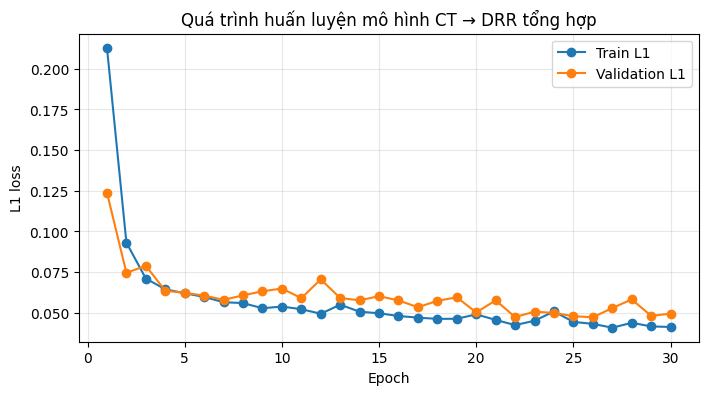

Đã nạp mô hình tốt nhất ở epoch: 26
Best validation L1: 0.047174


In [26]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(history["train_loss"]) + 1), history["train_loss"], marker="o", label="Train L1")
plt.plot(range(1, len(history["val_loss"]) + 1), history["val_loss"], marker="o", label="Validation L1")
plt.xlabel("Epoch")
plt.ylabel("L1 loss")
plt.title("Quá trình huấn luyện mô hình CT → DRR tổng hợp")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

checkpoint = torch.load(BEST_MODEL_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print("Đã nạp mô hình tốt nhất ở epoch:", checkpoint["epochs_completed"])
print("Best validation L1:", round(checkpoint["best_val_loss"], 6))

## Bước 9 — Đánh giá trên tập kiểm tra

Mô hình được đánh giá trên các ca CT giữ lại, không được sử dụng trực tiếp để cập nhật trọng số trong quá trình huấn luyện.

Các chỉ số được báo cáo:

- **MAE:** sai số tuyệt đối trung bình giữa ảnh dự đoán và ảnh tham chiếu.
- **PSNR:** tỷ số tín hiệu cực đại trên nhiễu, được tính từ sai số bình phương trên ảnh đã chuẩn hóa.

Chương trình cũng trực quan hóa CT đầu vào, ảnh tham chiếu và ảnh do mô hình dự đoán. Kết quả số được lưu trong `test_metrics.json`.

Vì mục tiêu đánh giá là ảnh chiếu tổng hợp được tạo từ CT, MAE và PSNR chỉ đo mức độ gần với mục tiêu đó. Hai chỉ số này không thể thay thế đánh giá chất lượng ảnh X-quang lâm sàng.

Kết quả tập kiểm tra:
Số ca: 6
MAE trung bình: 0.03974
PSNR trung bình: 25.88 dB


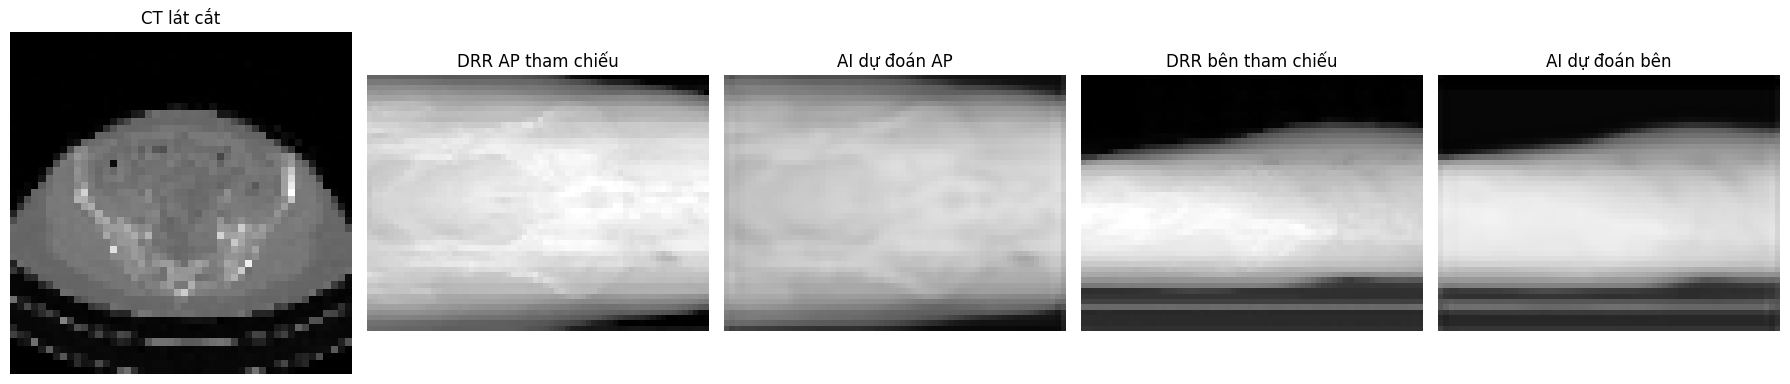

Đã lưu chỉ số: /content/ct_to_synthetic_xray/outputs/trained_model/test_metrics.json


In [27]:
def evaluate_loader(loader):
    model.eval()
    maes, psnrs = [], []
    predictions_for_plot = []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            pred = model(x)
            mae = torch.mean(torch.abs(pred - y)).item()
            mse = torch.mean((pred - y) ** 2).item()
            psnr = 99.0 if mse < 1e-10 else -10.0 * math.log10(mse)
            maes.append(mae)
            psnrs.append(psnr)
            if not predictions_for_plot:
                predictions_for_plot.append((x[0, 0].cpu().numpy(), y[0].cpu().numpy(), pred[0].cpu().numpy()))
    return {
        "MAE_mean": float(np.mean(maes)) if maes else float("nan"),
        "PSNR_mean_dB": float(np.mean(psnrs)) if psnrs else float("nan"),
        "num_cases": len(maes),
        "example": predictions_for_plot[0] if predictions_for_plot else None,
    }

metrics = evaluate_loader(test_loader)
print("Kết quả tập kiểm tra:")
print(f"Số ca: {metrics['num_cases']}")
print(f"MAE trung bình: {metrics['MAE_mean']:.5f}")
print(f"PSNR trung bình: {metrics['PSNR_mean_dB']:.2f} dB")

if metrics["example"] is not None:
    vol, ref, pred = metrics["example"]
    fig, ax = plt.subplots(1, 5, figsize=(18, 4))
    ax[0].imshow(vol[:, :, vol.shape[2] // 2].T, cmap="gray", origin="lower")
    ax[0].set_title("CT lát cắt")
    ax[1].imshow(ref[0], cmap="gray", origin="lower", vmin=0, vmax=1)
    ax[1].set_title("DRR AP tham chiếu")
    ax[2].imshow(pred[0], cmap="gray", origin="lower", vmin=0, vmax=1)
    ax[2].set_title("AI dự đoán AP")
    ax[3].imshow(ref[1], cmap="gray", origin="lower", vmin=0, vmax=1)
    ax[3].set_title("DRR bên tham chiếu")
    ax[4].imshow(pred[1], cmap="gray", origin="lower", vmin=0, vmax=1)
    ax[4].set_title("AI dự đoán bên")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

METRICS_PATH = OUTPUT_DIR / "test_metrics.json"
METRICS_PATH.write_text(json.dumps({k:v for k,v in metrics.items() if k != "example"}, indent=2), encoding="utf-8")
print("Đã lưu chỉ số:", METRICS_PATH)

## Bước 10 — Khám phá thể tích CT và xem kết quả dự đoán

Giao diện tương tác cho phép lựa chọn ca CT, vùng thể tích, mặt phẳng xem và chỉ số lát cắt.

Các vùng một phần gồm 1/3 trên, 1/3 giữa và 1/3 dưới theo trục không gian đã chuẩn hóa. Đây là cách chia thể tích tương đối, không phải công cụ xác định chính xác cơ quan giải phẫu.

Sau khi lựa chọn, chương trình hiển thị lát cắt CT cùng ảnh tham chiếu AP/Lateral và ảnh do mô hình dự đoán để hỗ trợ so sánh trực quan.

Các ảnh đầu ra là kết quả thử nghiệm phục vụ nghiên cứu, không dùng cho chẩn đoán.

In [28]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Lưu các ca đã xử lý trong bộ nhớ, và xử lý thêm khi người dùng chọn một ca khác.
prepared_by_path = {str(Path(c["path"]).resolve()): c for c in prepared_cases}


def get_case_for_view(path_str):
    key = str(Path(path_str).resolve())
    if key not in prepared_by_path:
        prepared_by_path[key] = prepare_case(Path(path_str))
    return prepared_by_path[key]


def crop_selected_region(volume, region):
    z = volume.shape[2]
    if region == "upper":
        return volume[:, :, max(0, (2 * z) // 3):]
    if region == "middle":
        return volume[:, :, z // 3:max(z // 3 + 1, (2 * z) // 3)]
    if region == "lower":
        return volume[:, :, :max(1, z // 3)]
    return volume


def fit_volume_shape(volume):
    tensor = torch.from_numpy(np.ascontiguousarray(volume)).float()[None, None]
    tensor = F.interpolate(tensor, size=TARGET_SHAPE, mode="trilinear", align_corners=False)
    return tensor


def axis_index(plane):
    return {"Sagittal (X)": 0, "Coronal (Y)": 1, "Axial (Z)": 2}[plane]


def display_selection(path_str, region, plane, slice_index):
    case = get_case_for_view(path_str)
    volume = crop_selected_region(case["volume"], region)
    idx_axis = axis_index(plane)
    actual_idx = min(int(slice_index), volume.shape[idx_axis] - 1)

    if idx_axis == 0:
        ct_slice = volume[actual_idx, :, :].T
    elif idx_axis == 1:
        ct_slice = volume[:, actual_idx, :].T
    else:
        ct_slice = volume[:, :, actual_idx].T

    # Mạng nhận kích thước cố định kể cả khi người xem chọn một vùng nhỏ.
    x = fit_volume_shape(volume).to(DEVICE)
    # Tạo ảnh tham chiếu từ chính thể tích sau khi resize về kích thước đầu vào cố định.
    resized_volume = x[0, 0].detach().cpu().numpy()
    ref = torch.from_numpy(make_reference_drr(resized_volume)[None]).float().to(DEVICE)
    with torch.no_grad():
        pred = model(x)
        mae = torch.mean(torch.abs(pred - ref)).item()
    pred = pred[0].detach().cpu().numpy()
    ref = ref[0].detach().cpu().numpy()

    fig, ax = plt.subplots(1, 5, figsize=(18, 4))
    ax[0].imshow(ct_slice, cmap="gray", origin="lower")
    ax[0].set_title(f"CT — {plane}\nLát {actual_idx + 1}/{volume.shape[idx_axis]}")
    ax[1].imshow(ref[0], cmap="gray", origin="lower", vmin=0, vmax=1)
    ax[1].set_title("AP tham chiếu DRR")
    ax[2].imshow(pred[0], cmap="gray", origin="lower", vmin=0, vmax=1)
    ax[2].set_title("AP do AI dự đoán")
    ax[3].imshow(ref[1], cmap="gray", origin="lower", vmin=0, vmax=1)
    ax[3].set_title("Lateral tham chiếu DRR")
    ax[4].imshow(pred[1], cmap="gray", origin="lower", vmin=0, vmax=1)
    ax[4].set_title("Lateral do AI dự đoán")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()
    print(f"Ca CT: {Path(path_str).name} | vùng: {region} | MAE so với DRR giả lập: {mae:.5f}")
    print("Lưu ý: đây là hình chiếu tổng hợp để nghiên cứu, không phải ảnh X-quang lâm sàng.")


case_dropdown = widgets.Dropdown(
    options=[(str(p.relative_to(DATASET_DIR)) if p.is_relative_to(DATASET_DIR) else p.name, str(p)) for p in ct_candidates],
    value=str(usable_paths[0]), description="Ca CT:", layout=widgets.Layout(width="95%")
)
region_dropdown = widgets.Dropdown(
    options=[("Toàn bộ thể tích", "full"), ("1/3 trên", "upper"), ("1/3 giữa", "middle"), ("1/3 dưới", "lower")],
    value="full", description="Vùng:", layout=widgets.Layout(width="55%")
)
plane_dropdown = widgets.Dropdown(
    options=[("Axial (Z)", "Axial (Z)"), ("Coronal (Y)", "Coronal (Y)"), ("Sagittal (X)", "Sagittal (X)")],
    value="Axial (Z)", description="Mặt phẳng:", layout=widgets.Layout(width="55%")
)
slice_slider = widgets.IntSlider(value=32, min=0, max=63, step=1, description="Lát cắt:", continuous_update=False, layout=widgets.Layout(width="75%"))


def set_slice_range(change=None):
    try:
        case = get_case_for_view(case_dropdown.value)
        v = crop_selected_region(case["volume"], region_dropdown.value)
        max_idx = v.shape[axis_index(plane_dropdown.value)] - 1
        slice_slider.max = max_idx
        if slice_slider.value > max_idx:
            slice_slider.value = max_idx
    except Exception as exc:
        print("Không cập nhật được số lát cắt:", exc)

for widget in (case_dropdown, region_dropdown, plane_dropdown):
    widget.observe(set_slice_range, names="value")

ui = widgets.VBox([case_dropdown, region_dropdown, plane_dropdown, slice_slider])
output = widgets.interactive_output(display_selection, {
    "path_str": case_dropdown,
    "region": region_dropdown,
    "plane": plane_dropdown,
    "slice_index": slice_slider,
})
set_slice_range()
display(ui, output)

Output()

## Bước 11 — Xuất mô hình và kết quả đánh giá

Trọng số mô hình tốt nhất và các tệp kết quả được lưu trong thư mục `outputs/trained_model/`, bao gồm:

- `best_model.pt`: trọng số và thông tin checkpoint.
- `training_history.json`: lịch sử Train L1 và Validation L1.
- `test_metrics.json`: các chỉ số đánh giá trên tập kiểm tra.

Chương trình tạo gói `trained_model_bundle.zip` tại thư mục gốc của dự án và tải gói về máy thông qua trình duyệt.

Hãy lưu các tệp cần thiết sau khi hoàn thành vì dữ liệu trong bộ nhớ phiên Colab có thể bị mất khi môi trường bị đặt lại.

In [29]:
import zipfile
from google.colab import files

BUNDLE_PATH = ROOT_DIR / "trained_model_bundle.zip"
with zipfile.ZipFile(BUNDLE_PATH, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in OUTPUT_DIR.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=str(Path("trained_model") / p.relative_to(OUTPUT_DIR)))
print("Đã tạo:", BUNDLE_PATH, f"({BUNDLE_PATH.stat().st_size / 1024**2:.2f} MB)")
files.download(str(BUNDLE_PATH))

Đã tạo: /content/ct_to_synthetic_xray/trained_model_bundle.zip (0.03 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Giới hạn và hướng phát triển

1. **Mục tiêu tổng hợp:** mô hình học dự đoán các ảnh chiếu được tạo từ CT bằng phép chiếu trung bình. Đây không phải bài toán học chuyển đổi CT sang ảnh X-quang thật đã được xác nhận.
2. **Phạm vi dữ liệu:** notebook hiện hỗ trợ CT NIfTI. Muốn áp dụng cho MRI cần dữ liệu MRI và quy trình tiền xử lý phù hợp.
3. **Độ phân giải:** thể tích đầu vào được giảm kích thước để phù hợp với tài nguyên Colab, làm hạn chế lượng chi tiết có thể giữ lại.
4. **Khả năng tổng quát hóa:** số lượng ca mẫu còn hạn chế. Cần đánh giá trên nhiều dữ liệu độc lập hơn trước khi đưa ra kết luận về hiệu quả mô hình.
5. **Chỉ số đánh giá:** MAE và PSNR phản ánh mức độ gần với ảnh tham chiếu tổng hợp, không phải thước đo độ chính xác chẩn đoán.
6. **Ứng dụng y tế:** kết quả chỉ dành cho học tập và nghiên cứu, không dùng để chẩn đoán, điều trị hoặc thay thế quy trình chụp y khoa.

## Hướng phát triển tiếp theo

- Tăng số lượng dữ liệu và đánh giá trên tập độc lập.
- So sánh ảnh dự đoán với mục tiêu tham chiếu bằng cả chỉ số định lượng và trực quan.
- Cải thiện cách tạo ảnh chiếu tham chiếu và đánh giá tính hợp lý về mặt hình ảnh.
- Bổ sung hướng dẫn tái lập thực nghiệm, phiên bản thư viện và thông tin cấu hình huấn luyện.